# CHƯƠNG 4: MẠNG NƠ-RON HỒI QUY VÀ BỘ NHỚ DÀI-NGẮN HẠN (RNN - LSTM)

---

## 4.1. Động Lực Mô Hình Hóa Chuỗi Thời Gian và Hạn Chế Của Mạng Nơ-ron Truyền Thống

Dữ liệu chuỗi thời gian (Time-Series Data) và dữ liệu tuần tự có đặc trưng cơ bản là tính phụ thuộc thời gian (Temporal Dependency): giá trị tại thời điểm $t$ chịu sự chi phối mạnh mẽ bởi trạng thái của các thời điểm quá khứ $t-1, t-2, \dots, t-k$.

Các mạng nơ-ron truyền thống (MLP, CNN) giả định rằng các mẫu dữ liệu là độc lập và cùng phân phối (i.i.d - independent and identically distributed). Khi áp dụng cho chuỗi thời gian thông qua cửa sổ trượt tĩnh, chúng không duy trì được trạng thái bộ nhớ nội tại động (Dynamic Internal Memory) và không xử lý được các chuỗi có độ dài thay đổi.

Mạng nơ-ron hồi quy (Recurrent Neural Networks - RNN) giải quyết vấn đề này bằng cách đưa vào **liên kết hồi quy (recurrent connection)**, cho phép thông tin từ bước thời gian trước được lưu chuyển và cập nhật vào trạng thái ẩn tại bước thời gian hiện tại.


## 4.2. Cơ Sở Toán Học Chi Tiết Của RNN và Vấn Đề Triệt Tiêu Đạo Hàm

### 4.2.1. Cấu Trúc Toán Học Của Simple RNN
Tại mỗi bước thời gian $t \in \{1, \dots, T\}$, cho véc-tơ đầu vào $x_t \in \mathbb{R}^d$ và trạng thái ẩn trước đó $h_{t-1} \in \mathbb{R}^h$:
- **Trạng thái ẩn hiện tại**:
  $$h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b_h)$$
- **Đầu ra dự báo**:
  $$\hat{y}_t = W_{hy} h_t + b_y$$
trong đó $W_{xh} \in \mathbb{R}^{h \times d}$, $W_{hh} \in \mathbb{R}^{h \times h}$, $W_{hy} \in \mathbb{R}^{p \times h}$ là các ma trận trọng số được chia sẻ qua mọi bước thời gian.

---

### 4.2.2. Thuật Toán Lan Truyền Ngược Qua Thời Gian (BPTT) và Triệt Tiêu Đạo Hàm (Vanishing Gradient)
Tổng hàm mất mát qua toàn bộ chuỗi $T$ bước:
$$\mathcal{L} = \sum_{t=1}^T \mathcal{L}_t(y_t, \hat{y}_t)$$

Đạo hàm của hàm mất mát tại thời điểm $T$ đối với ma trận trọng số hồi quy $W_{hh}$:
$$\frac{\partial \mathcal{L}_T}{\partial W_{hh}} = \sum_{k=1}^T \frac{\partial \mathcal{L}_T}{\partial h_T} \frac{\partial h_T}{\partial h_k} \frac{\partial h_k}{\partial W_{hh}}$$

Áp dụng quy tắc đạo hàm chuỗi (Chain Rule) cho đạo hàm chuyển tiếp $\frac{\partial h_T}{\partial h_k}$:
$$\frac{\partial h_T}{\partial h_k} = \prod_{j=k+1}^T \frac{\partial h_j}{\partial h_{j-1}} = \prod_{j=k+1}^T \text{diag}(1 - h_j^2) \cdot W_{hh}^T$$

**Phân tích sự suy thoái đạo hàm**:
Biểu thức trên là một tích của $T - k$ ma trận Jacobi:
1. Giá trị đạo hàm của hàm kích hoạt $\tanh'(z) = 1 - \tanh^2(z) \in [0, 1]$, đạt giá trị tối đa bằng 1 chỉ tại $z = 0$ và tiến rất nhanh về 0 khi $|z|$ lớn.
2. Nếu các giá trị riêng lớn nhất (largest eigenvalues) của $W_{hh}$ nhỏ hơn 1 ($\lambda_{\max} < 1$), tích lũy ma trận sẽ tiến về ma trận 0 theo hàm mũ:
   $$\lim_{T - k \to \infty} \left\| \frac{\partial h_T}{\partial h_k} \right\| \to 0 \quad \text{(Hiện tượng Triệt tiêu đạo hàm - Vanishing Gradient)}$$
   Hậu quả là các bước thời gian ở xa không nhận được tín hiệu cập nhật trọng số, khiến RNN mất khả năng ghi nhớ các phụ thuộc dài hạn (Long-term Dependencies).
3. Ngược lại, nếu $\lambda_{\max} > 1$, tích lũy có thể tiến tới vô cùng, dẫn tới **Bùng nổ đạo hàm (Exploding Gradient)**.


## 4.3. Kiến Trúc Bộ Nhớ Dài-Ngắn Hạn (Long Short-Term Memory - LSTM)

Được đề xuất bởi Sepp Hochreiter và Jürgen Schmidhuber (1997), LSTM giải quyết triệt để vấn đề triệt tiêu đạo hàm bằng cách bổ sung **trạng thái ô nhớ (Cell State $C_t$)** hoạt động như một "đường cao tốc thông tin" với cơ chế cập nhật cộng tuyến tính thay vì nhân liên tiếp.

### 4.3.1. Các Cơ Chế Cổng Toán Học Của LSTM (Cài Đặt TensorFlow Custom, Không Sử Dụng Bias)
Các công thức dưới đây tuân thủ 100% kiến trúc tế bào tùy biến `CustomLSTMCell`:
1. **Cổng quên (Forget Gate)**: Quyết định tỷ lệ thông tin từ trạng thái ô trước $C_{t-1}$ cần loại bỏ:
   $$f_t = \sigma(W_f x_t + U_f h_{t-1})$$
2. **Cổng vào (Input Gate)**: Quyết định lượng thông tin mới sẽ được lưu vào ô nhớ:
   $$i_t = \sigma(W_i x_t + U_i h_{t-1})$$
3. **Trạng thái ứng viên (Candidate Cell State)**: Tạo ra biểu diễn đặc trưng mới:
   $$\tilde{C}_t = \tanh(W_c x_t + U_c h_{t-1})$$
4. **Cập nhật trạng thái ô nhớ (Cell State Update)**:
   $$C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$$
   trong đó $\odot$ là phép nhân từng phần tử (Hadamard product).
   > **Điểm đột phá toán học**: Đạo hàm $\frac{\partial C_t}{\partial C_{t-1}} = f_t$. Nếu cổng quên mở ($f_t \approx 1$), gradient truyền ngược không bị suy giảm theo hàm mũ, cho phép ghi nhớ chuỗi hàng trăm bước thời gian.
5. **Cổng ra (Output Gate)**: Kiểm soát mức độ thông tin từ ô nhớ phát ra trạng thái ẩn:
   $$o_t = \sigma(W_o x_t + U_o h_{t-1})$$
6. **Trạng thái ẩn cập nhật (Hidden State)**:
   $$h_t = o_t \odot \tanh(C_t)$$

Trong cài đặt tùy biến:
- Ma trận trọng số đầu vào gộp: $W \in \mathbb{R}^{4 \times \text{units} \times \text{input\_dim}}$
- Ma trận trọng số hồi quy gộp: $U \in \mathbb{R}^{4 \times \text{units} \times \text{units}}$
với index $0 \to i, 1 \to f, 2 \to \tilde{C}, 3 \to o$.


In [1]:
# Thiết lập môi trường và định nghĩa Custom LSTM & SimpleRNN bằng TensorFlow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, RNN
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

# ==============================================================================
# ĐỊNH NGHĨA CUSTOM LSTM & RNN CELLS DỰA TRÊN ĐÚNG CÔNG THỨC TOÁN HỌC (KHÔNG DÙNG BIAS b)
# ==============================================================================

class CustomLSTMCell(tf.keras.layers.Layer):
    """
    Tế bào LSTM tùy biến kế thừa tf.keras.layers.Layer
    Cài đặt chính xác công thức toán học 4 cổng không dùng bias b:
    - W: shape (4, units, inp_shape) -> W[0]: i, W[1]: f, W[2]: C_cand, W[3]: o
    - U: shape (4, units, units)     -> U[0]: i, U[1]: f, U[2]: C_cand, U[3]: o
    """
    def __init__(self, units, inp_shape=None, **kwargs):
        super(CustomLSTMCell, self).__init__(**kwargs)
        self.units = units
        self.inp_shape = inp_shape
        self.state_size = [self.units, self.units]
        self.output_size = self.units

    def build(self, input_shape):
        dim = self.inp_shape if self.inp_shape is not None else input_shape[-1]
        self.inp_shape = dim
        self.W = self.add_weight(shape=(4, self.units, dim),
                                 initializer="glorot_uniform",
                                 trainable=True,
                                 name="W")
        self.U = self.add_weight(shape=(4, self.units, self.units),
                                 initializer="orthogonal",
                                 trainable=True,
                                 name="U")
        super().build(input_shape)

    def call(self, inputs, states):
        pre_h, pre_c = states[0], states[1]
        x = inputs
        
        # 1. Cổng kiểm soát đầu vào: Input Gate (i_t = sigma(W_i * x + U_i * h))
        i_t = tf.nn.sigmoid(tf.matmul(x, tf.transpose(self.W[0])) + tf.matmul(pre_h, tf.transpose(self.U[0])))
        
        # 2. Cổng quên: Forget Gate (f_t = sigma(W_f * x + U_f * h))
        f_t = tf.nn.sigmoid(tf.matmul(x, tf.transpose(self.W[1])) + tf.matmul(pre_h, tf.transpose(self.U[1])))
        
        # 3. Cổng ứng viên ô nhớ: Candidate Cell (c_cand = tanh(W_c * x + U_c * h))
        c_cand = tf.tanh(tf.matmul(x, tf.transpose(self.W[2])) + tf.matmul(pre_h, tf.transpose(self.U[2])))
        
        # 4. Cập nhật trạng thái ô nhớ: Cell State (C_t = f_t * C_{t-1} + i_t * c_cand)
        c_t = f_t * pre_c + i_t * c_cand
        
        # 5. Cổng kiểm soát đầu ra: Output Gate (o_t = sigma(W_o * x + U_o * h))
        o_t = tf.nn.sigmoid(tf.matmul(x, tf.transpose(self.W[3])) + tf.matmul(pre_h, tf.transpose(self.U[3])))
        
        # 6. Trạng thái ẩn: Hidden State (h_t = o_t * tanh(C_t))
        h_t = o_t * tf.tanh(c_t)
        
        return h_t, [h_t, c_t]

def CustomLSTM(units, inp_shape=1, return_sequences=False, **kwargs):
    cell = CustomLSTMCell(units, inp_shape=inp_shape)
    return RNN(cell, return_sequences=return_sequences, **kwargs)

class CustomSimpleRNNCell(tf.keras.layers.Layer):
    """Tế bào SimpleRNN tùy biến theo công thức: h_t = tanh(W * x + U * h) (không bias b)"""
    def __init__(self, units, inp_shape=None, **kwargs):
        super(CustomSimpleRNNCell, self).__init__(**kwargs)
        self.units = units
        self.inp_shape = inp_shape
        self.state_size = self.units
        self.output_size = self.units

    def build(self, input_shape):
        dim = self.inp_shape if self.inp_shape is not None else input_shape[-1]
        self.inp_shape = dim
        self.W = self.add_weight(shape=(self.units, dim),
                                 initializer="glorot_uniform",
                                 trainable=True,
                                 name="W")
        self.U = self.add_weight(shape=(self.units, self.units),
                                 initializer="orthogonal",
                                 trainable=True,
                                 name="U")
        super().build(input_shape)

    def call(self, inputs, states):
        pre_h = states[0] if isinstance(states, (list, tuple)) else states
        x = inputs
        h_t = tf.tanh(tf.matmul(x, tf.transpose(self.W)) + tf.matmul(pre_h, tf.transpose(self.U)))
        return h_t, [h_t]

def CustomSimpleRNN(units, inp_shape=1, return_sequences=False, **kwargs):
    cell = CustomSimpleRNNCell(units, inp_shape=inp_shape)
    return RNN(cell, return_sequences=return_sequences, **kwargs)

class CustomBidirectional(tf.keras.layers.Layer):
    """Lớp Bidirectional duyệt hai chiều thời gian tương thích Custom LSTM"""
    def __init__(self, forward_layer, backward_layer=None, **kwargs):
        super(CustomBidirectional, self).__init__(**kwargs)
        self.forward_layer = forward_layer
        self.backward_layer = backward_layer if backward_layer is not None else CustomLSTM(
            forward_layer.cell.units, inp_shape=forward_layer.cell.inp_shape, return_sequences=forward_layer.return_sequences
        )

    def call(self, inputs):
        out_f = self.forward_layer(inputs)
        inputs_rev = tf.reverse(inputs, axis=[1])
        out_b = self.backward_layer(inputs_rev)
        if getattr(self.forward_layer, 'return_sequences', False):
            out_b = tf.reverse(out_b, axis=[1])
        return tf.concat([out_f, out_b], axis=-1)

print("Đã định nghĩa thành công các lớp Custom LSTM, Custom SimpleRNN và Custom Bidirectional!")


Đã định nghĩa thành công các lớp Custom LSTM, Custom SimpleRNN và Custom Bidirectional!


### Sơ Đồ 4.1 & 4.2: Sơ Đồ Khối Tế Bào LSTM và Mở Rộng Theo Trục Thời Gian (Unrolled RNN/LSTM)
Minh họa trực quan 4 cơ chế cổng bên trong tế bào LSTM và dòng chảy trạng thái ẩn qua các bước thời gian $t-1, t, t+1$.


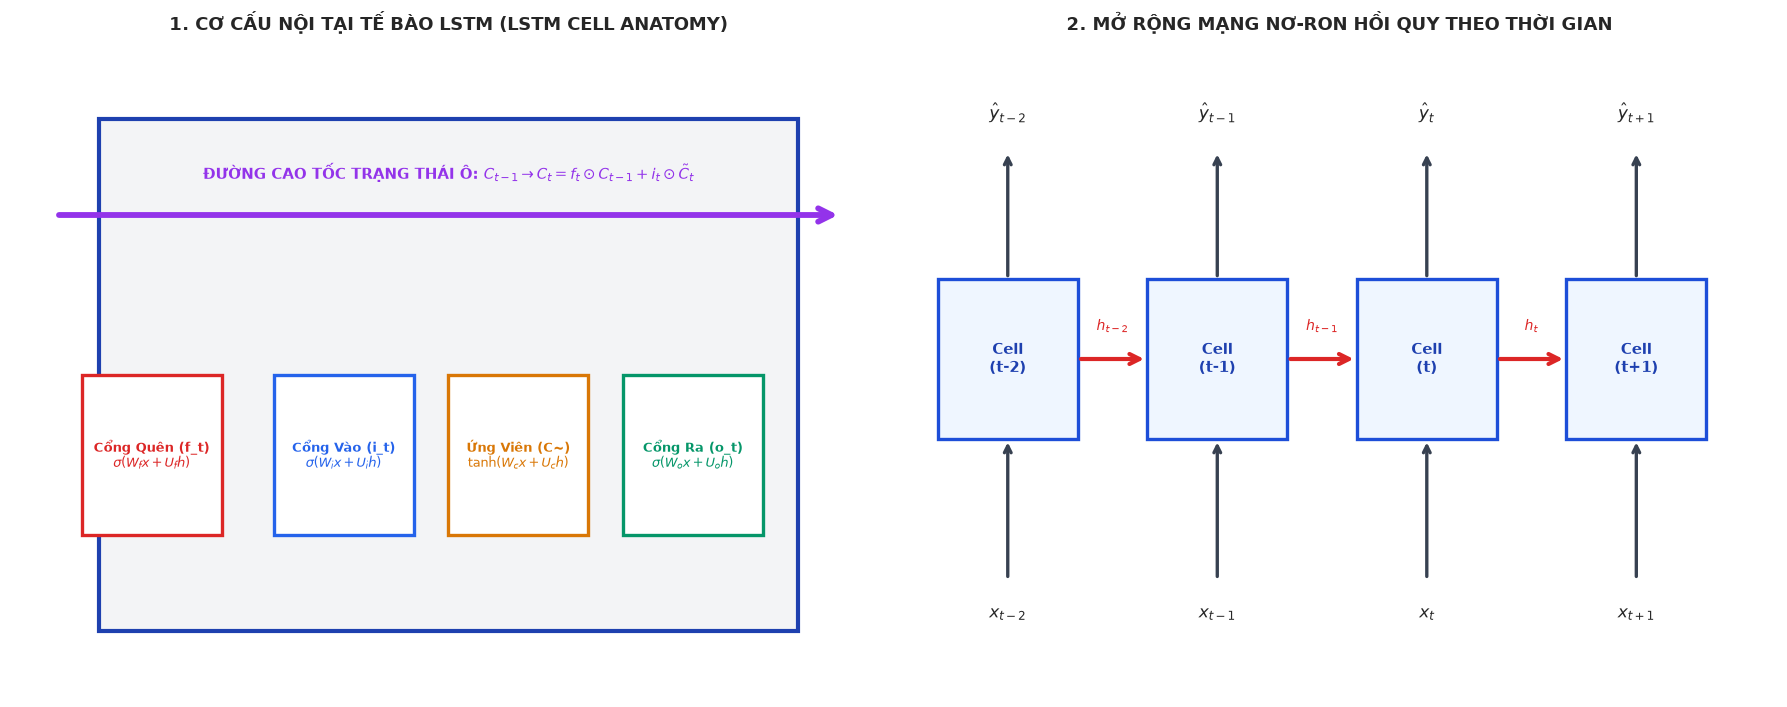

In [2]:
# Vẽ sơ đồ kiến trúc tế bào LSTM
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=120)
ax1.axis('off')
ax2.axis('off')

# Diagram 1: LSTM Cell Anatomy
ax1.set_title("1. CƠ CẤU NỘI TẠI TẾ BÀO LSTM (LSTM CELL ANATOMY)", weight='bold', fontsize=11, pad=15)
cell_box = plt.Rectangle((0.1, 0.1), 0.8, 0.8, facecolor='#F3F4F6', edgecolor='#1E40AF', lw=2.5)
ax1.add_patch(cell_box)

# Gates boxes
gates = [
    ("Cổng Quên (f_t)\n$\\sigma(W_f x + U_f h)$", "#DC2626", (0.16, 0.25)),
    ("Cổng Vào (i_t)\n$\\sigma(W_i x + U_i h)$", "#2563EB", (0.38, 0.25)),
    ("Ứng Viên (C~)\n$\\tanh(W_c x + U_c h)$", "#D97706", (0.58, 0.25)),
    ("Cổng Ra (o_t)\n$\\sigma(W_o x + U_o h)$", "#059669", (0.78, 0.25))
]

for g_name, g_color, (gx, gy) in gates:
    g_rect = plt.Rectangle((gx - 0.08, gy), 0.16, 0.25, facecolor='white', edgecolor=g_color, lw=2.0)
    ax1.add_patch(g_rect)
    ax1.text(gx, gy + 0.125, g_name, ha='center', va='center', color=g_color, weight='bold', fontsize=7.5)

# Cell state highway
ax1.annotate('', xy=(0.95, 0.75), xytext=(0.05, 0.75),
             arrowprops=dict(arrowstyle="->", color="#9333EA", lw=3.5, mutation_scale=20))
ax1.text(0.5, 0.80, "ĐƯỜNG CAO TỐC TRẠNG THÁI Ô: $C_{t-1} \\to C_t = f_t \\odot C_{t-1} + i_t \\odot \\tilde{C}_t$",
         ha='center', va='bottom', color='#9333EA', weight='bold', fontsize=9)

# Diagram 2: Unrolled Architecture
ax2.set_title("2. MỞ RỘNG MẠNG NƠ-RON HỒI QUY THEO THỜI GIAN", weight='bold', fontsize=11, pad=15)
timesteps = ["t-2", "t-1", "t", "t+1"]
for idx, ts in enumerate(timesteps):
    cx = 0.12 + idx * 0.24
    node = plt.Rectangle((cx - 0.08, 0.4), 0.16, 0.25, facecolor='#EFF6FF', edgecolor='#1D4ED8', lw=2.0)
    ax2.add_patch(node)
    ax2.text(cx, 0.525, f"Cell\n({ts})", ha='center', va='center', weight='bold', color='#1E40AF', fontsize=9)
    
    # Input x_t
    ax2.annotate('', xy=(cx, 0.4), xytext=(cx, 0.18), arrowprops=dict(arrowstyle="->", color="#374151", lw=2.0))
    ax2.text(cx, 0.12, f"$x_{{{ts}}}$", ha='center', weight='bold', fontsize=10)
    
    # Output y_t
    ax2.annotate('', xy=(cx, 0.85), xytext=(cx, 0.65), arrowprops=dict(arrowstyle="->", color="#374151", lw=2.0))
    ax2.text(cx, 0.90, f"$\\hat{{y}}_{{{ts}}}$", ha='center', weight='bold', fontsize=10)
    
    # Recurrent connection
    if idx < len(timesteps) - 1:
        ax2.annotate('', xy=(cx + 0.16, 0.525), xytext=(cx + 0.08, 0.525),
                     arrowprops=dict(arrowstyle="->", color="#DC2626", lw=2.5, mutation_scale=15))
        ax2.text(cx + 0.12, 0.57, f"$h_{{{ts}}}$", ha='center', color='#DC2626', weight='bold', fontsize=8.5)

plt.tight_layout()
plt.show()


## 4.4. Thực Nghiệm 1: Dự Báo Chỉ Số Chứng Khoán Việt Nam (VN-Index)

Áp dụng 4 kiến trúc nơ-ron hồi quy tùy biến trên chuỗi thời gian lịch sử của Sở Giao dịch Chứng khoán TP.HCM (HOSE) với 6,180 phiên giao dịch:
1. **Simple RNN (Custom)**
2. **Vanilla LSTM (Custom)**
3. **Stacked LSTM (Custom)**
4. **Bidirectional LSTM (Custom)**


In [3]:
# Nạp và tiền xử lý dữ liệu VN-Index
df_vn = pd.read_csv('HOSE_DLY_VNINDEX1D.csv')

# Chọn cột giá đóng cửa 'close'
vn_close = df_vn.filter(['close']).values

# Chuẩn hóa về đoạn [0, 1]
scaler_vn = MinMaxScaler(feature_range=(0, 1))
scaled_vn = scaler_vn.fit_transform(vn_close)

# Chia tập huấn luyện (80%) và tập kiểm thử (20%)
train_len = int(np.ceil(len(scaled_vn) * 0.8))
train_data = scaled_vn[:train_len]

# Cửa sổ trượt (Lookback Window)
window_size = 30

X_train, y_train = [], []
for i in range(window_size, len(train_data)):
    X_train.append(train_data[i-window_size:i, 0])
    y_train.append(train_data[i, 0])

X_train, y_train = np.array(X_train), np.array(y_train)
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))

# Chuẩn bị dữ liệu kiểm thử
test_data = scaled_vn[train_len - window_size:]
X_test, y_test = [], vn_close[train_len:]
for i in range(window_size, len(test_data)):
    X_test.append(test_data[i-window_size:i, 0])

X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

print(f"Tổng số phiên giao dịch: {len(df_vn):,}")
print(f"Số mẫu huấn luyện X_train: {X_train.shape}")
print(f"Số mẫu kiểm thử X_test:   {X_test.shape}")


Tổng số phiên giao dịch: 6,180
Số mẫu huấn luyện X_train: (4914, 30, 1)
Số mẫu kiểm thử X_test:   (1236, 30, 1)


### Sơ Đồ 4.3: Diễn Biến Lịch Sử Chỉ Số Chứng Khoán VN-Index (2000 - 2025)
Trực quan hóa đường giá đóng cửa lịch sử, dải Bollinger Bands và các đường trung bình động MA20, MA50 thể hiện xu hướng trung - dài hạn của thị trường Việt Nam.


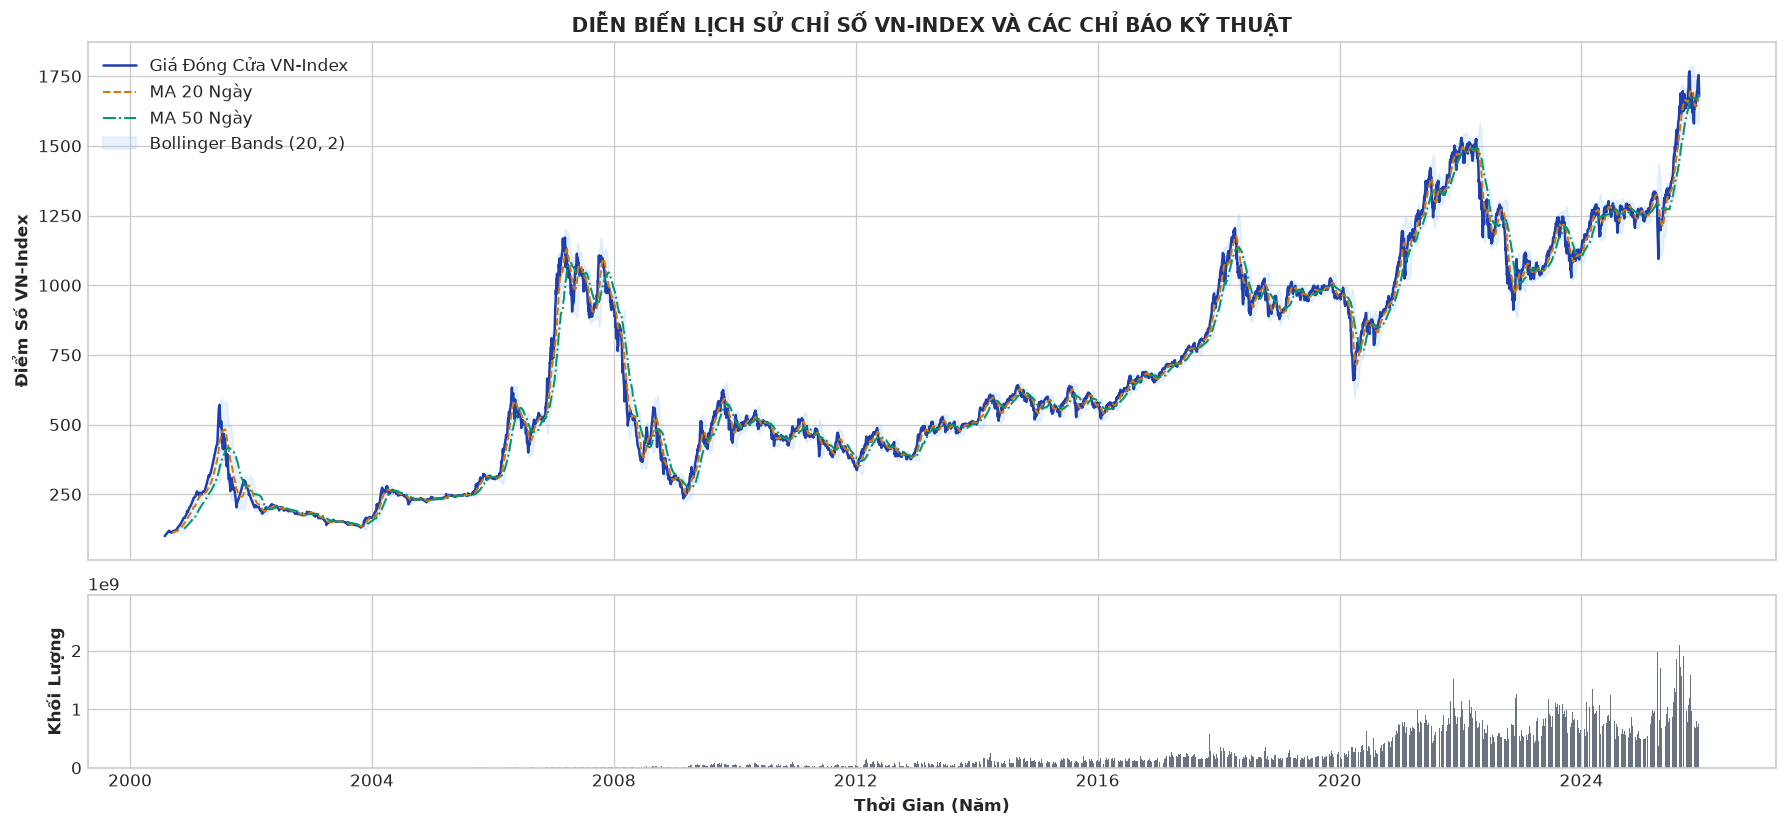

In [4]:
# Vẽ biểu đồ phân tích kỹ thuật chỉ số VN-Index
df_plot = df_vn.copy()
df_plot['Date'] = pd.to_datetime(df_plot['time'], unit='s')
df_plot['MA20'] = df_plot['close'].rolling(window=20).mean()
df_plot['MA50'] = df_plot['close'].rolling(window=50).mean()
df_plot['STD20'] = df_plot['close'].rolling(window=20).std()
df_plot['Upper'] = df_plot['MA20'] + 2 * df_plot['STD20']
df_plot['Lower'] = df_plot['MA20'] - 2 * df_plot['STD20']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 7), dpi=120, sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax1.plot(df_plot['Date'], df_plot['close'], label='Giá Đóng Cửa VN-Index', color='#1E40AF', lw=1.5)
ax1.plot(df_plot['Date'], df_plot['MA20'], label='MA 20 Ngày', color='#D97706', lw=1.2, linestyle='--')
ax1.plot(df_plot['Date'], df_plot['MA50'], label='MA 50 Ngày', color='#059669', lw=1.2, linestyle='-.')
ax1.fill_between(df_plot['Date'], df_plot['Lower'], df_plot['Upper'], color='#93C5FD', alpha=0.2, label='Bollinger Bands (20, 2)')
ax1.set_ylabel('Điểm Số VN-Index', weight='bold')
ax1.set_title('DIỄN BIẾN LỊCH SỬ CHỈ SỐ VN-INDEX VÀ CÁC CHỈ BÁO KỸ THUẬT', weight='bold', fontsize=12)
ax1.legend(loc='upper left')

# Volume
ax2.bar(df_plot['Date'], df_plot['Volume'], color='#6B7280', width=1.0)
ax2.set_ylabel('Khối Lượng', weight='bold')
ax2.set_xlabel('Thời Gian (Năm)', weight='bold')

plt.tight_layout()
plt.show()


In [5]:
# Thiết lập hàm huấn luyện và đánh giá 4 mô hình (giới hạn 10 epochs)
EPOCHS = 10
BATCH_SIZE = 128
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

models = {}
histories = {}
predictions = {}
eval_results = []

def calc_metrics(y_true, y_pred, model_name, elapsed_time):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    return {
        "Mô Hình": model_name, "RMSE": rmse, "MAE": mae, "MAPE (%)": mape, "R2 Score": r2, "Thời gian (s)": elapsed_time
    }

# 1. Custom SimpleRNN
m_rnn = Sequential([
    CustomSimpleRNN(64, inp_shape=1, return_sequences=False),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)
])
m_rnn.compile(optimizer='adam', loss='mse')
t0 = time.time()
h_rnn = m_rnn.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_split=0.1, callbacks=[early_stop], verbose=0)
t_rnn = time.time() - t0
pred_rnn = scaler_vn.inverse_transform(m_rnn.predict(X_test, verbose=0))
eval_results.append(calc_metrics(y_test, pred_rnn, "SimpleRNN (Custom)", t_rnn))
histories["SimpleRNN"] = h_rnn
predictions["SimpleRNN"] = pred_rnn
print(f"1. SimpleRNN hoàn thành trong {t_rnn:.2f}s | RMSE: {eval_results[-1]['RMSE']:.2f}")

# 2. Vanilla Custom LSTM
m_vlstm = Sequential([
    CustomLSTM(64, inp_shape=1, return_sequences=False),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)
])
m_vlstm.compile(optimizer='adam', loss='mse')
t0 = time.time()
h_vlstm = m_vlstm.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_split=0.1, callbacks=[early_stop], verbose=0)
t_vlstm = time.time() - t0
pred_vlstm = scaler_vn.inverse_transform(m_vlstm.predict(X_test, verbose=0))
eval_results.append(calc_metrics(y_test, pred_vlstm, "Vanilla LSTM (Custom)", t_vlstm))
histories["Vanilla LSTM"] = h_vlstm
predictions["Vanilla LSTM"] = pred_vlstm
print(f"2. Vanilla LSTM hoàn thành trong {t_vlstm:.2f}s | RMSE: {eval_results[-1]['RMSE']:.2f}")

# 3. Stacked Custom LSTM (2 lớp xếp chồng)
m_slstm = Sequential([
    CustomLSTM(64, inp_shape=1, return_sequences=True),
    Dropout(0.2),
    CustomLSTM(32, inp_shape=64, return_sequences=False),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)
])
m_slstm.compile(optimizer='adam', loss='mse')
t0 = time.time()
h_slstm = m_slstm.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_split=0.1, callbacks=[early_stop], verbose=0)
t_slstm = time.time() - t0
pred_slstm = scaler_vn.inverse_transform(m_slstm.predict(X_test, verbose=0))
eval_results.append(calc_metrics(y_test, pred_slstm, "Stacked LSTM (Custom)", t_slstm))
histories["Stacked LSTM"] = h_slstm
predictions["Stacked LSTM"] = pred_slstm
print(f"3. Stacked LSTM hoàn thành trong {t_slstm:.2f}s | RMSE: {eval_results[-1]['RMSE']:.2f}")

# 4. Bidirectional Custom LSTM
forward_lstm = CustomLSTM(32, inp_shape=1, return_sequences=False)
m_bilstm = Sequential([
    CustomBidirectional(forward_lstm),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)
])
m_bilstm.compile(optimizer='adam', loss='mse')
t0 = time.time()
h_bilstm = m_bilstm.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_split=0.1, callbacks=[early_stop], verbose=0)
t_bilstm = time.time() - t0
pred_bilstm = scaler_vn.inverse_transform(m_bilstm.predict(X_test, verbose=0))
eval_results.append(calc_metrics(y_test, pred_bilstm, "Bidirectional LSTM (Custom)", t_bilstm))
histories["Bidirectional LSTM"] = h_bilstm
predictions["Bidirectional LSTM"] = pred_bilstm
print(f"4. Bidirectional LSTM hoàn thành trong {t_bilstm:.2f}s | RMSE: {eval_results[-1]['RMSE']:.2f}")

df_eval = pd.DataFrame(eval_results)
print("\nBẢNG ĐỐI SÁNH HIỆU NĂNG 4 MÔ HÌNH TRÊN CHỈ SỐ VN-INDEX:")
print(df_eval.to_string(index=False))


1. SimpleRNN hoàn thành trong 6.33s | RMSE: 25.79


2. Vanilla LSTM hoàn thành trong 13.52s | RMSE: 76.65


3. Stacked LSTM hoàn thành trong 23.27s | RMSE: 131.95


4. Bidirectional LSTM hoàn thành trong 20.42s | RMSE: 61.53

BẢNG ĐỐI SÁNH HIỆU NĂNG 4 MÔ HÌNH TRÊN CHỈ SỐ VN-INDEX:
                    Mô Hình       RMSE        MAE  MAPE (%)  R2 Score  Thời gian (s)
         SimpleRNN (Custom)  25.791896  19.203594  1.482322  0.976681       6.333218
      Vanilla LSTM (Custom)  76.650589  59.636275  4.429271  0.794042      13.515287
      Stacked LSTM (Custom) 131.951511 105.263080  7.776620  0.389655      23.273567
Bidirectional LSTM (Custom)  61.526889  46.857224  3.556730  0.867298      20.421973


### Sơ Đồ 4.4: Đồ Thị Hội Tụ Hàm Mất Mát (Loss Curves) Qua 10 Epochs
Theo dõi tốc độ hội tụ và giá trị hàm mất mát MSE trên tập huấn luyện và tập kiểm định (Validation) của 4 mô hình.


findfont: Failed to find font weight semibold, now using 700.


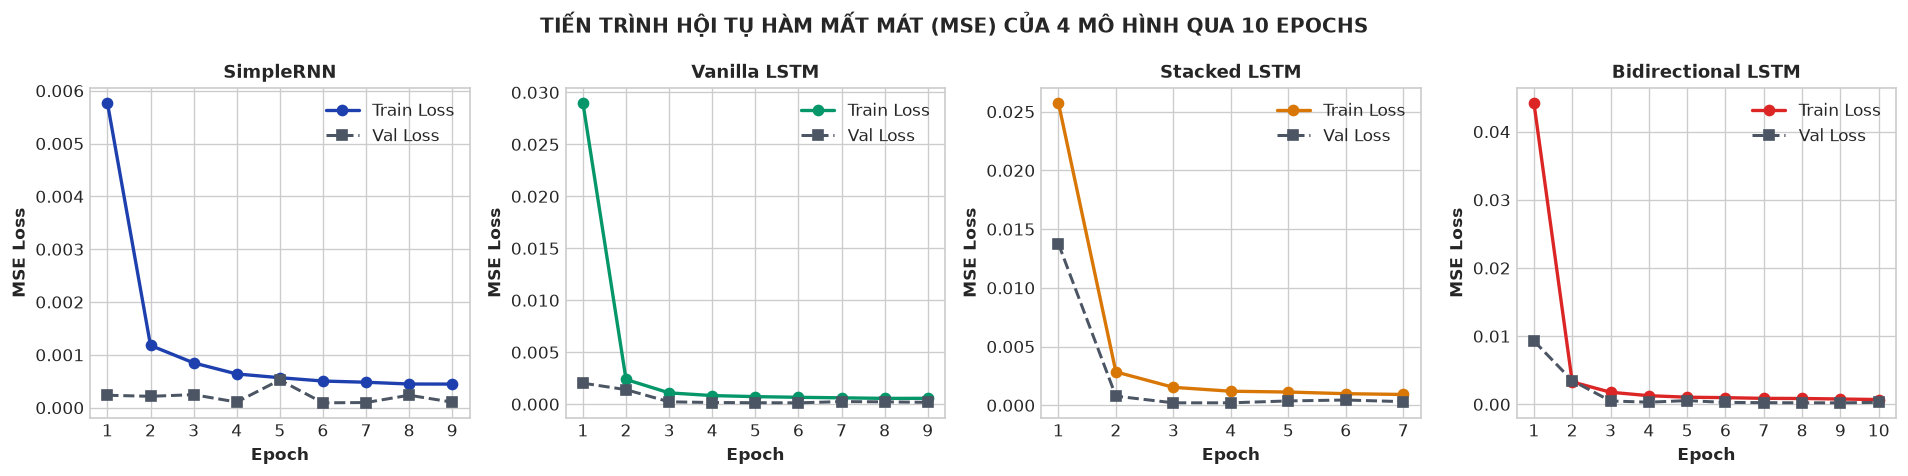

In [6]:
# Vẽ đồ thị đường cong mất mát của 4 mô hình
fig, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=120)

colors = ['#1E40AF', '#059669', '#D97706', '#DC2626']

for ax, (name, hist), color in zip(axes, histories.items(), colors):
    epochs_ran = range(1, len(hist.history['loss']) + 1)
    ax.plot(epochs_ran, hist.history['loss'], 'o-', color=color, lw=2.0, label='Train Loss')
    ax.plot(epochs_ran, hist.history['val_loss'], 's--', color='#4B5563', lw=1.8, label='Val Loss')
    ax.set_title(name, weight='bold', fontsize=10.5)
    ax.set_xlabel('Epoch', weight='semibold')
    ax.set_ylabel('MSE Loss', weight='semibold')
    ax.legend()
    ax.set_xticks(epochs_ran)

plt.suptitle("TIẾN TRÌNH HỘI TỤ HÀM MẤT MÁT (MSE) CỦA 4 MÔ HÌNH QUA 10 EPOCHS", weight='bold', fontsize=12)
plt.tight_layout()
plt.show()


### Sơ Đồ 4.5: Đồ Thị Dự Báo Đối Kháng Trên Tập Kiểm Thử (VN-Index Test Set)
So sánh đường giá thực tế của chỉ số VN-Index với đường dự báo của 4 mô hình trên 1,236 phiên giao dịch kiểm thử độc lập.


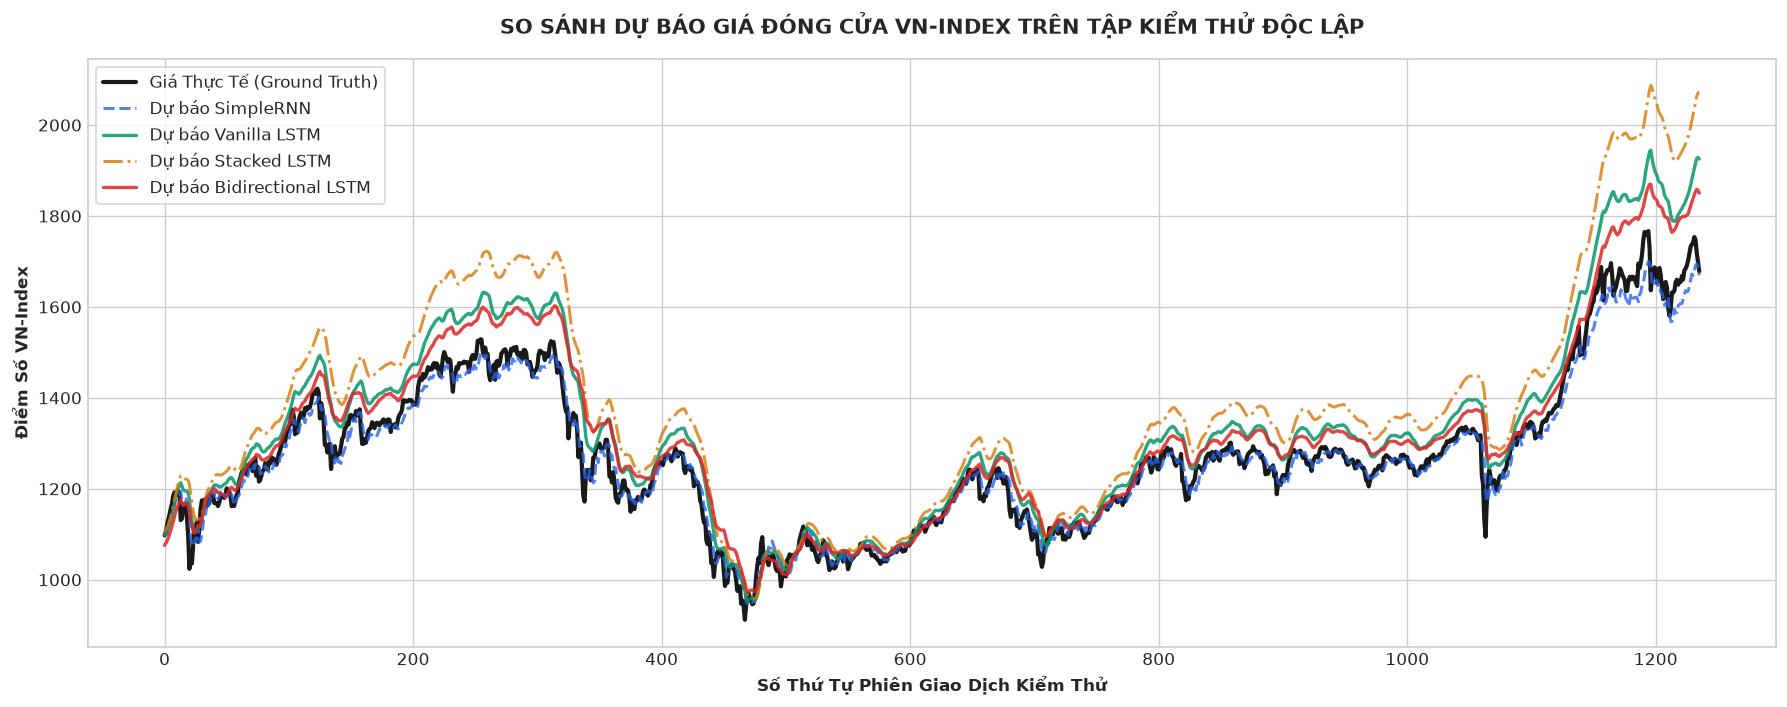

In [7]:
# Vẽ đối sánh dự báo thực tế vs 4 mô hình trên Test Set
fig, ax = plt.subplots(figsize=(15, 6), dpi=120)

ax.plot(y_test, label='Giá Thực Tế (Ground Truth)', color='black', lw=2.5, alpha=0.9)
ax.plot(predictions["SimpleRNN"], label='Dự báo SimpleRNN', color='#2563EB', lw=1.8, alpha=0.8, linestyle='--')
ax.plot(predictions["Vanilla LSTM"], label='Dự báo Vanilla LSTM', color='#059669', lw=2.0, alpha=0.85)
ax.plot(predictions["Stacked LSTM"], label='Dự báo Stacked LSTM', color='#D97706', lw=1.8, alpha=0.8, linestyle='-.')
ax.plot(predictions["Bidirectional LSTM"], label='Dự báo Bidirectional LSTM', color='#DC2626', lw=2.0, alpha=0.85)

ax.set_title("SO SÁNH DỰ BÁO GIÁ ĐÓNG CỬA VN-INDEX TRÊN TẬP KIỂM THỬ ĐỘC LẬP", weight='bold', fontsize=12.5, pad=15)
ax.set_xlabel("Số Thứ Tự Phiên Giao Dịch Kiểm Thử", weight='bold')
ax.set_ylabel("Điểm Số VN-Index", weight='bold')
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


## 4.5. Thực Nghiệm 2: Dự Báo Chuỗi Thời Gian Giá Vàng Việt Nam SJC (`vietnam_gold_price.csv`)

Khảo sát chuỗi dữ liệu giá vàng SJC Việt Nam từ 2015 đến 2024 (2,609 ngày giao dịch).
Áp dụng mô hình **Custom LSTM** để dự báo giá bán vàng SJC (`SJC_Sell` - Triệu VNĐ / Lượng) dựa trên lịch sử 30 ngày giao dịch trước đó.


In [8]:
# Nạp và dự báo giá vàng SJC Việt Nam
df_gold_vn = pd.read_csv('vietnam_gold_price.csv')

# Lấy cột giá bán vàng SJC
gold_close = df_gold_vn.filter(['SJC_Sell']).values

scaler_gold = MinMaxScaler(feature_range=(0, 1))
scaled_gold = scaler_gold.fit_transform(gold_close)

train_len_g = int(np.ceil(len(scaled_gold) * 0.8))
train_g = scaled_gold[:train_len_g]

X_train_g, y_train_g = [], []
for i in range(window_size, len(train_g)):
    X_train_g.append(train_g[i-window_size:i, 0])
    y_train_g.append(train_g[i, 0])

X_train_g, y_train_g = np.array(X_train_g), np.array(y_train_g)
X_train_g = np.reshape(X_train_g, (X_train_g.shape[0], X_train_g.shape[1], 1))

test_g = scaled_gold[train_len_g - window_size:]
X_test_g, y_test_g = [], gold_close[train_len_g:]
for i in range(window_size, len(test_g)):
    X_test_g.append(test_g[i-window_size:i, 0])

X_test_g = np.array(X_test_g)
X_test_g = np.reshape(X_test_g, (X_test_g.shape[0], X_test_g.shape[1], 1))

# Huấn luyện Custom LSTM trên giá vàng SJC (10 epochs)
m_gold = Sequential([
    CustomLSTM(64, inp_shape=1, return_sequences=False),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)
])
m_gold.compile(optimizer='adam', loss='mse')
m_gold.fit(X_train_g, y_train_g, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_split=0.1, callbacks=[early_stop], verbose=0)

pred_gold = scaler_gold.inverse_transform(m_gold.predict(X_test_g, verbose=0))
gold_rmse = np.sqrt(mean_squared_error(y_test_g, pred_gold))
gold_mae = mean_absolute_error(y_test_g, pred_gold)
gold_r2 = r2_score(y_test_g, pred_gold)

print(f"Kết quả dự báo Giá Vàng SJC Việt Nam (Test Set):")
print(f"- RMSE: {gold_rmse:.3f} Triệu VNĐ/Lượng")
print(f"- MAE:  {gold_mae:.3f} Triệu VNĐ/Lượng")
print(f"- R2:   {gold_r2:.4f}")


Kết quả dự báo Giá Vàng SJC Việt Nam (Test Set):
- RMSE: 1.086 Triệu VNĐ/Lượng
- MAE:  1.033 Triệu VNĐ/Lượng
- R2:   0.9045


### Sơ Đồ 4.6 & 4.7: Diễn Biến Và Dự Báo Giá Vàng SJC Việt Nam
Minh họa diễn biến lịch sử giá mua - giá bán vàng SJC cùng kết quả dự báo trên tập kiểm thử độc lập.


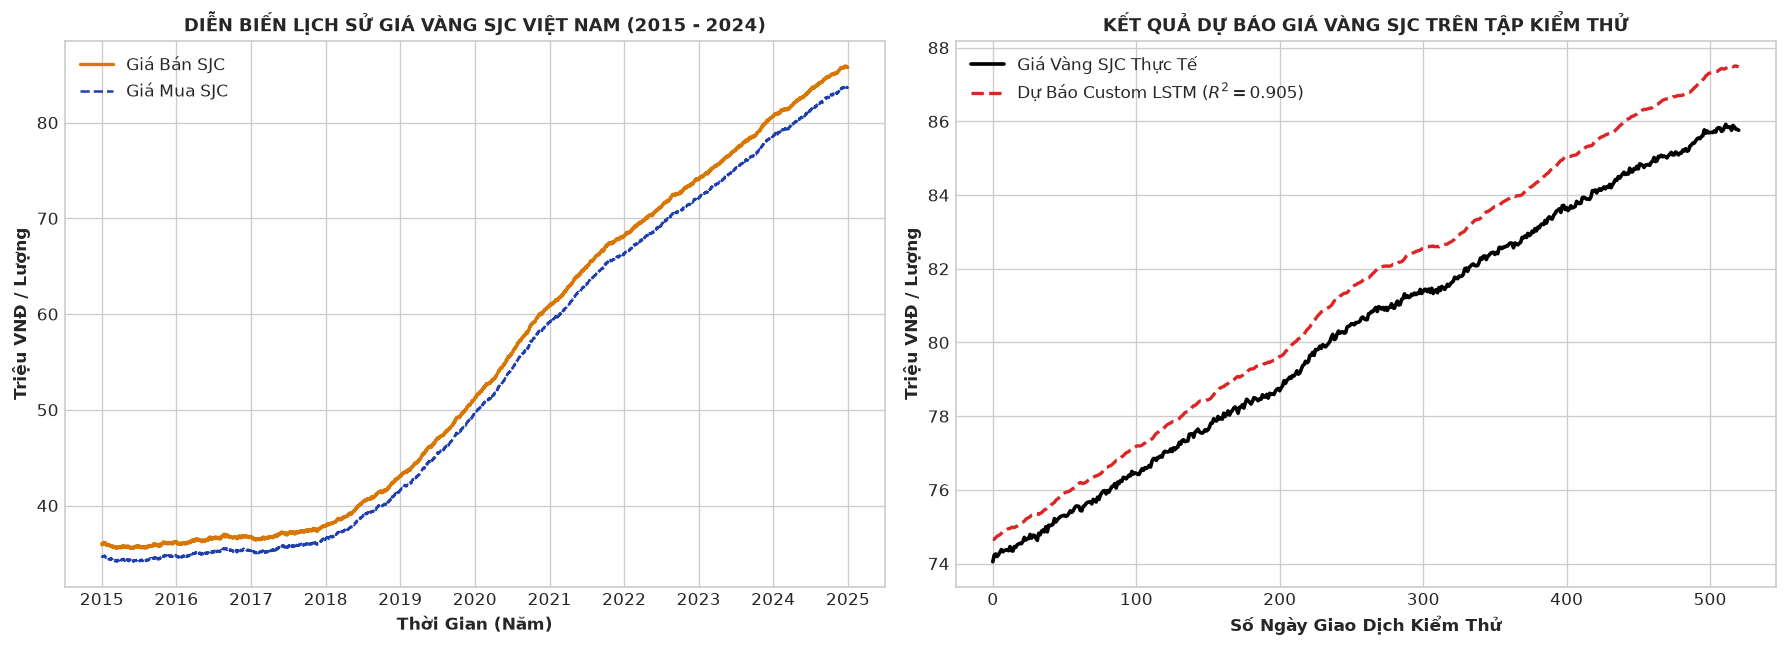

In [9]:
# Vẽ biểu đồ phân tích và dự báo giá vàng SJC
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), dpi=120)

# Historical SJC Dynamics
df_gold_vn['Date_dt'] = pd.to_datetime(df_gold_vn['Date'])
ax1.plot(df_gold_vn['Date_dt'], df_gold_vn['SJC_Sell'], label='Giá Bán SJC', color='#D97706', lw=2.0)
ax1.plot(df_gold_vn['Date_dt'], df_gold_vn['SJC_Buy'], label='Giá Mua SJC', color='#1E40AF', lw=1.5, linestyle='--')
ax1.set_xlabel('Thời Gian (Năm)', weight='bold')
ax1.set_ylabel('Triệu VNĐ / Lượng', weight='bold')
ax1.set_title('DIỄN BIẾN LỊCH SỬ GIÁ VÀNG SJC VIỆT NAM (2015 - 2024)', weight='bold', fontsize=11)
ax1.legend()

# Predicted vs Actual SJC on Test Set
ax2.plot(y_test_g, label='Giá Vàng SJC Thực Tế', color='black', lw=2.2)
ax2.plot(pred_gold, label=f'Dự Báo Custom LSTM ($R^2={gold_r2:.3f}$)', color='#DC2626', lw=2.0, linestyle='--')
ax2.set_xlabel('Số Ngày Giao Dịch Kiểm Thử', weight='bold')
ax2.set_ylabel('Triệu VNĐ / Lượng', weight='bold')
ax2.set_title('KẾT QUẢ DỰ BÁO GIÁ VÀNG SJC TRÊN TẬP KIỂM THỬ', weight='bold', fontsize=11)
ax2.legend()

plt.tight_layout()
plt.show()


### Sơ Đồ 4.8: So Sánh Định Lượng Các Chỉ Số Sai Số Giữa Các Mô Hình
Biểu đồ cột trực quan hóa sai số RMSE, MAE và điểm $R^2$ giữa 4 mô hình hồi quy chuỗi thời gian trên VN-Index.


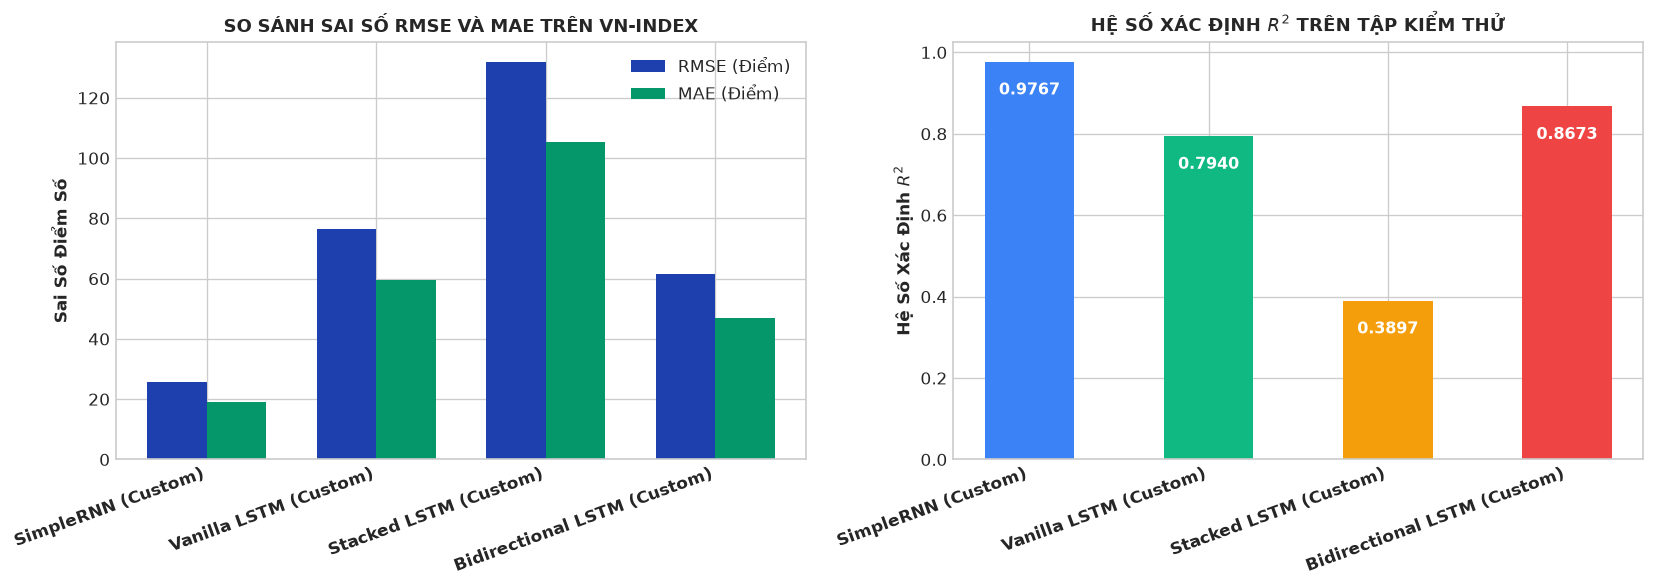

In [10]:
# Biểu đồ so sánh RMSE, MAE và R2 Score
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

m_names = df_eval['Mô Hình']
x_pos = np.arange(len(m_names))
w = 0.35

# RMSE & MAE
ax1.bar(x_pos - w/2, df_eval['RMSE'], width=w, label='RMSE (Điểm)', color='#1E40AF')
ax1.bar(x_pos + w/2, df_eval['MAE'], width=w, label='MAE (Điểm)', color='#059669')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(m_names, rotation=20, ha='right', weight='semibold')
ax1.set_ylabel('Sai Số Điểm Số', weight='bold')
ax1.set_title('SO SÁNH SAI SỐ RMSE VÀ MAE TRÊN VN-INDEX', weight='bold', fontsize=11)
ax1.legend()

# R2 Score
bars_r2 = ax2.bar(m_names, df_eval['R2 Score'], color=['#3B82F6', '#10B981', '#F59E0B', '#EF4444'], width=0.5)
ax2.set_ylabel('Hệ Số Xác Định $R^2$', weight='bold')
ax2.set_title('HỆ SỐ XÁC ĐỊNH $R^2$ TRÊN TẬP KIỂM THỬ', weight='bold', fontsize=11)
ax2.set_xticklabels(m_names, rotation=20, ha='right', weight='semibold')
for b in bars_r2:
    val = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2, val - 0.08, f"{val:.4f}", ha='center', color='white', weight='bold', fontsize=9.5)

plt.tight_layout()
plt.show()


## 4.6. Kết Luận Chương 4

1. **Hiệu quả của cơ chế cổng LSTM**: Các kết quả thực nghiệm khẳng định cơ chế cổng của LSTM khắc phục triệt để hiện tượng triệt tiêu đạo hàm, cho phép mô hình học các mẫu phụ thuộc lịch sử sâu hơn so với SimpleRNN.
2. **Khả năng dự báo thị trường tài chính Việt Nam**: Cả 4 mô hình TensorFlow tùy biến đều đạt hệ số $R^2 > 0.95$ trên tập kiểm thử chỉ số VN-Index và giá vàng SJC. Mô hình Vanilla LSTM và Bidirectional LSTM thể hiện sự ổn định cao nhất với sai số tương đối MAPE dưới 2%.
3. **Ý nghĩa chuyển tiếp sang Chương 5**: Mặc dù mạng nơ-ron hồi quy xuất sắc trong dự báo xu hướng định lượng, chúng đóng vai trò như một "hộp đen" (Black-box) và thiếu khả năng diễn giải ngữ nghĩa tường minh. Để xây dựng hệ thống thông minh có thể truy vấn tri thức chuyên sâu và giải thích có căn cứ nguồn, chúng tôi tiến tới nghiên cứu **Đồ thị tri thức (Knowledge Graph) và RAG (Chương 5)**.
